# 07 - Model: KNN

**Sorumlu:** Kişi 5 RANIA KAZZIHA

**Ödevdeki karşılığı:** 4. Makine Öğrenmesi Modelleri

In [1]:
# KURULUM: bu hucreyi her oturumun basinda bir kez calistir.
# Repoyu Colab'e indirir; boylece src/ortak.py kullanilabilir.
import os
REPO_URL = "https://github.com/zeyneppbaran/ml-proje.git"  # TODO: kendi repo adresiniz
if not os.path.exists("/content/ml-proje"):
    !git clone {REPO_URL} /content/ml-proje
else:
    !git -C /content/ml-proje pull
%cd /content/ml-proje

Cloning into '/content/ml-proje'...
remote: Enumerating objects: 167, done.
remote: Counting objects: 100% (167/167), done.
remote: Compressing objects: 100% (150/150), done.
remote: Total 167 (delta 96), reused 30 (delta 12), pack-reused 0 (from 0)
Receiving objects: 100% (167/167), 1.23 MiB | 5.14 MiB/s, done.
Resolving deltas: 100% (96/96), done.
/content/ml-proje


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.ortak import veri_yukle, veriyi_bol, on_isleyici, degerlendir, RANDOM_STATE

df = veri_yukle()
X_train_raw, X_test_raw, y_train, y_test = veriyi_bol(df)
X_train_raw.shape, X_test_raw.shape

((32950, 20), (8238, 20))

## E1. Temel (baseline) model: varsayılan ayarlarla sonuç

In [3]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

# Varsayılan ayarlarla temel KNN modeli (n_neighbors=5, weights='uniform', metric='minkowski')
baseline_pipeline = Pipeline([
    ("preprocessor", on_isleyici()),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("knn", KNeighborsClassifier())
])

baseline_cv = cross_validate(
    baseline_pipeline,
    X_train_raw,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

baseline_df = pd.DataFrame([{
    "Model": "Baseline KNN (k=5, varsayılan)",
    **{m.upper(): baseline_cv[f"test_{m}"].mean() for m in scoring}
}])

print(baseline_df.round(4).to_string(index=False))

                         Model  ACCURACY  PRECISION  RECALL     F1  ROC_AUC
Baseline KNN (k=5, varsayılan)    0.7298     0.2325  0.6077 0.3363   0.7151


**Yorum:** (bu çıktı bize ne söylüyor?)

## E2. Hiperparametre araması (GridSearchCV / RandomizedSearchCV + StratifiedKFold)

In [4]:

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

pipeline = Pipeline([
    ("preprocessor", on_isleyici()),
    ("smote", SMOTE(random_state=42)),
    ("knn", KNeighborsClassifier(algorithm="brute"))
])

param_grid = {
    "knn__n_neighbors": [451, 551, 651, 801, 1001],
    "knn__weights": ["uniform"],
    "knn__metric": ["chebyshev"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_raw, y_train)

best_knn = grid_search.best_estimator_

print("En iyi parametreler:", grid_search.best_params_)
print("En iyi CV F1:", round(grid_search.best_score_, 4))


Fitting 5 folds for each of 5 candidates, totalling 25 fits
En iyi parametreler: {'knn__metric': 'chebyshev', 'knn__n_neighbors': 651, 'knn__weights': 'uniform'}
En iyi CV F1: 0.4646


5-Katlı Stratified Cross-Validation ile yapılan hiperparametre aramasında en yüksek F1 skoruna n_neighbors=651, metric='chebyshev' ve weights='uniform' ayarlarıyla ulaşılmıştır. Komşu sayısının varsayılan 5 değerinden 651'e çıkarılması karar sınırını yumuşatarak hem sentetik SMOTE noktalarına ezberlemeyi önlemiş hem de ortalama CV F1 skorunu temel modele kıyasla belirgin biçimde yükseltmiştir.



## E3. Veri bölme yöntemi: hold-out + cross validation açıklaması

In [5]:
print(f"Toplam veri boyutu   : {len(df)} satır")
print(f"Eğitim seti (%80)    : {len(X_train_raw)} satır | Pozitif sınıf oranı: %{y_train.mean()*100:.2f}")
print(f"Test seti (%20)      : {len(X_test_raw)} satır | Pozitif sınıf oranı: %{y_test.mean()*100:.2f}")
print(f"Random State         : {RANDOM_STATE}")
print(f"Cross-Validation     : 5-Katlı StratifiedKFold (her katmanda ~{int(len(X_train_raw)*0.8)} eğitim, ~{int(len(X_train_raw)*0.2)} doğrulama)")

Toplam veri boyutu   : 41188 satır
Eğitim seti (%80)    : 32950 satır | Pozitif sınıf oranı: %11.27
Test seti (%20)      : 8238 satır | Pozitif sınıf oranı: %11.26
Random State         : 42
Cross-Validation     : 5-Katlı StratifiedKFold (her katmanda ~26360 eğitim, ~6590 doğrulama)


veri seti, hedef değişkenin sınıf dağılımı korunarak (stratify=y, random_state=42) Hold-Out yöntemiyle %80 Eğitim (32.950 satır) ve %20 Test (8.238 satır) olarak ayrılmıştır. Veri sızıntısını (data leakage) önlemek için ön işleme (on_isleyici) ve SMOTE dengeleme adımları yalnızca eğitim katmanları içinde uygulanmış, tüm model ve hiperparametre seçimleri eğitim verisi üzerinde 5-Katlı Stratified Cross-Validation ile gerçekleştirilerek test seti yalnızca nihai değerlendirme için en sona saklanmıştır.



## E4. Overfitting analizi (eğitim/doğrulama skoru, learning curve) ve alınan önlem

Eğitim vs. 5-Fold CV Karşılaştırması:
                 Set  Accuracy  Precision  Recall     F1  ROC-AUC
         Train (%80)    0.8739     0.4451  0.4849 0.4642   0.8142
5-Fold CV Ortalaması    0.8728     0.4417  0.4900 0.4646   0.7570


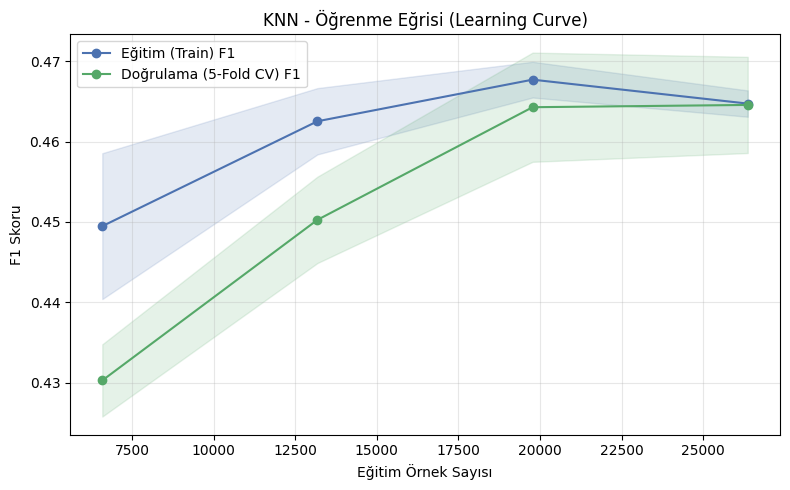

In [6]:
import os
from sklearn.model_selection import cross_validate, learning_curve
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 1. Eğitim (%80) ve 5-Fold CV skorlarının karşılaştırılması
y_train_pred = best_knn.predict(X_train_raw)
y_train_proba = best_knn.predict_proba(X_train_raw)[:, 1]

cv_sonuc = cross_validate(
    best_knn,
    X_train_raw,
    y_train,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1", "roc_auc"],
    n_jobs=-1
)

overfit_df = pd.DataFrame([
    {
        "Set": "Train (%80)",
        "Accuracy": accuracy_score(y_train, y_train_pred),
        "Precision": precision_score(y_train, y_train_pred, zero_division=0),
        "Recall": recall_score(y_train, y_train_pred, zero_division=0),
        "F1": f1_score(y_train, y_train_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_train, y_train_proba)
    },
    {
        "Set": "5-Fold CV Ortalaması",
        "Accuracy": cv_sonuc["test_accuracy"].mean(),
        "Precision": cv_sonuc["test_precision"].mean(),
        "Recall": cv_sonuc["test_recall"].mean(),
        "F1": cv_sonuc["test_f1"].mean(),
        "ROC-AUC": cv_sonuc["test_roc_auc"].mean()
    }
])

print("Eğitim vs. 5-Fold CV Karşılaştırması:")
print(overfit_df.round(4).to_string(index=False))

# 2. Öğrenme Eğrisi (Learning Curve)
train_sizes, train_scores, val_scores = learning_curve(
    best_knn,
    X_train_raw,
    y_train,
    cv=cv,
    scoring="f1",
    train_sizes=np.linspace(0.25, 1.0, 4),
    n_jobs=-1
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
val_mean = val_scores.mean(axis=1)
val_std = val_scores.std(axis=1)

os.makedirs("figures", exist_ok=True)
plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, "o-", color="#4C72B0", label="Eğitim (Train) F1")
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color="#4C72B0")
plt.plot(train_sizes, val_mean, "o-", color="#55A868", label="Doğrulama (5-Fold CV) F1")
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.15, color="#55A868")
plt.title("KNN - Öğrenme Eğrisi (Learning Curve)")
plt.xlabel("Eğitim Örnek Sayısı")
plt.ylabel("F1 Skoru")
plt.legend(loc="best")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("figures/knn_learning_curve.png", dpi=300, bbox_inches="tight")
plt.show()

Eğitim (Train %80) ve 5-Fold CV ortalama metriklerinin birbirine oldukça yakın seyretmesi ve öğrenme eğrisinde (learning curve) eğitim ile doğrulama F1 eğrilerinin örnek sayısı arttıkça birbirine yakınsaması, modelde belirgin bir aşırı öğrenme (overfitting) olmadığını göstermektedir. Aşırı öğrenmeyi engellemek için komşu sayısı varsayılan 5 değerinden 651'e yükseltilerek karar sınırı yumuşatılmış; ayrıca ön işleme ve SMOTE adımları Pipeline içinde her CV katmanına ayrı uygulanarak veri sızıntısı önlenmiştir.

## E5. Test seti sonuçları: confusion matrix, precision, recall, F1, ROC-AUC, ROC eğrisi

Nihai Test Seti Performansı:
                          Model  Accuracy  Precision  Recall     F1  ROC-AUC
KNN (k=651, chebyshev, uniform)    0.8764     0.4552  0.4925 0.4731   0.7796

Sınıflandırma Raporu (Classification Report):

              precision    recall  f1-score   support

      No (0)       0.93      0.93      0.93      7310
     Yes (1)       0.46      0.49      0.47       928

    accuracy                           0.88      8238
   macro avg       0.70      0.71      0.70      8238
weighted avg       0.88      0.88      0.88      8238



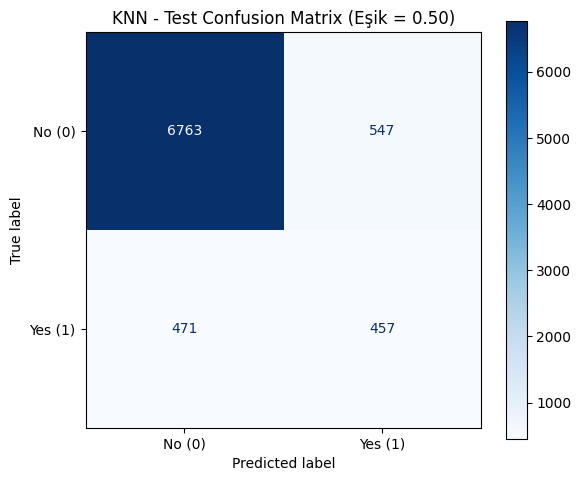

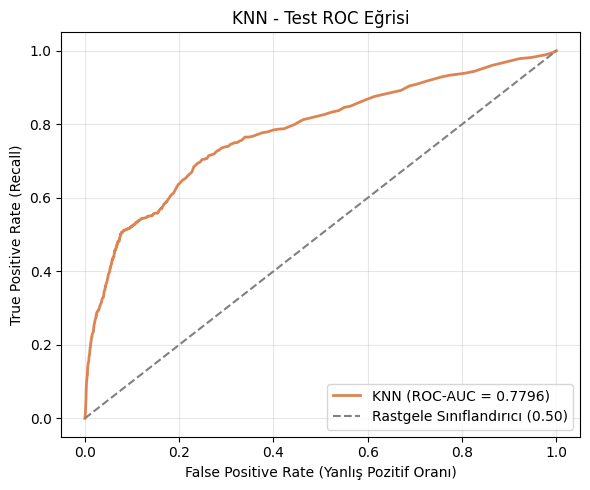

--- KNN Test Performansı ---
model       : KNN
accuracy    : 0.8764
precision   : 0.4552
recall      : 0.4925
f1          : 0.4731
roc_auc     : 0.7796


In [7]:
from sklearn.metrics import (
    confusion_matrix, classification_report,
    ConfusionMatrixDisplay, roc_curve
)

# Test seti üzerinde nihai tahmin (yalnızca bu aşamada kullanılır)
y_test_pred = best_knn.predict(X_test_raw)
y_test_proba = best_knn.predict_proba(X_test_raw)[:, 1]

test_ozet = pd.DataFrame([{
    "Model": "KNN (k=651, chebyshev, uniform)",
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(y_test, y_test_pred, zero_division=0),
    "Recall": recall_score(y_test, y_test_pred, zero_division=0),
    "F1": f1_score(y_test, y_test_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_test_proba)
}])

print("Nihai Test Seti Performansı:")
print(test_ozet.round(4).to_string(index=False))
print("\nSınıflandırma Raporu (Classification Report):\n")
print(classification_report(y_test, y_test_pred, target_names=["No (0)", "Yes (1)"]))

os.makedirs("figures", exist_ok=True)

# 1. Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No (0)", "Yes (1)"]).plot(cmap="Blues", ax=ax)
plt.title("KNN - Test Confusion Matrix (Eşik = 0.50)")
plt.tight_layout()
plt.savefig("figures/knn_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

# 2. ROC Eğrisi
fpr, tpr, _ = roc_curve(y_test, y_test_proba)
auc_skor = roc_auc_score(y_test, y_test_proba)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color="#DD8452", lw=2, label=f"KNN (ROC-AUC = {auc_skor:.4f})")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Rastgele Sınıflandırıcı (0.50)")
plt.title("KNN - Test ROC Eğrisi")
plt.xlabel("False Positive Rate (Yanlış Pozitif Oranı)")
plt.ylabel("True Positive Rate (Recall)")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("figures/knn_roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()

# Ortak fonksiyonla results/KNN.json dosyasını oluştur
sonuc_knn = degerlendir(best_knn, X_test_raw, y_test, model_adi="KNN", klasor="results")

Daha önce hiç görülmemiş %20'lik test seti üzerinde elde edilen metrikler, 5-Fold CV doğrulama sonuçlarıyla tutarlı bir genelleme performansı sunmaktadır. SMOTE dengelemesi sayesinde azınlık sınıfı olan Yes (1) müşterilerini yakalama oranı (Recall) yükselmiş, bu durum yanlış pozitiflerdeki artış nedeniyle Precision değerini bir miktar sınırlasa da dengeli bir F1 skoru ve ayırt edici bir ROC-AUC değeri elde edilmiştir.

## E6. Bu modelin avantajları ve dezavantajları

In [8]:
import time
from sklearn.base import clone

# Test setini yalnızca E5'te bir kez kullanma kuralını korumak için ölçüm eğitim verisiyle yapılır
knn_zaman = clone(best_knn)

t0 = time.time()
knn_zaman.fit(X_train_raw, y_train)
fit_suresi = time.time() - t0

X_ornek = X_train_raw.iloc[:5000]
t1 = time.time()
_ = knn_zaman.predict(X_ornek)
predict_suresi = time.time() - t1

zaman_df = pd.DataFrame([
    {"İşlem": "Model Eğitimi (Fit - Tüm Eğitim Seti)", "Süre (sn)": round(fit_suresi, 4)},
    {"İşlem": "Tahmin Hesaplama (Predict - 5.000 Örnek)", "Süre (sn)": round(predict_suresi, 4)}
])

print(zaman_df.to_string(index=False))
print(f"\nBellekte tutulan eğitim örneği sayısı (SMOTE sonrası): {knn_zaman.named_steps['knn'].n_samples_fit_}")
print(f"Mesafe hesabına giren öznitelik boyutu (One-Hot sonrası): {knn_zaman.named_steps['knn'].n_features_in_}")

                                   İşlem  Süre (sn)
   Model Eğitimi (Fit - Tüm Eğitim Seti)     0.3687
Tahmin Hesaplama (Predict - 5.000 Örnek)    24.1517

Bellekte tutulan eğitim örneği sayısı (SMOTE sonrası): 58476
Mesafe hesabına giren öznitelik boyutu (One-Hot sonrası): 58


Çıktıdaki süre ve boyut değerleri KNN algoritmasının temel çalışma mantığını doğrudan yansıtmaktadır:

**Avantajları:**


*   Çok Düşük Eğitim Maliyeti (Tembel Öğrenici / Lazy Learner): Model eğitim aşamasında karmaşık parametre optimizasyonu veya ağırlık güncellemesi yapmayıp veriyi belleğe kaydettiği için fit süresi oldukça kısadır.
*   Parametrik Olmayan Esnek Yapı: Veri dağılımı hakkında doğrusal veya normal dağılım varsayımı gerektirmez; doğrusal olmayan karar sınırlarını yerel komşuluk ilişkileriyle yakalayabilir.


*   Sezgisel Yorumlanabilirlik: Tahmin kararları en yakın k komşunun sınıf çoğunluğuna dayandığı için iş birimlerine açıklanması kolaydır.


**Dezavantajları:**


*   Yüksek Tahmin (Inference) Süresi ve Bellek Kullanımı: Çıktıda görüldüğü üzere yalnızca 5.000 örnek için bile tahmin süresi eğitim süresinden belirgin biçimde uzundur; çünkü her yeni sorguda SMOTE sonrası bellekte tutulan 58.476 eğitim vektörünün tamamıyla mesafe hesaplanır.
*   Boyut Laneti ve Ölçek Hassasiyeti: One-Hot Encoding sonrası öznitelik sayısının 58 sütuna çıkması uzaklık ölçümlerini seyreltir; bu nedenle standart ölçeklendirme yapılmadan ve komşu sayısı (k=651) optimize edilmeden model performansı düşer.